python -m venv .venv

.venv\Scripts\activate.bat

python -m pip install pandas numpy matplotlib seaborn scikit-learn scipy jupyter ipykernel

jupyter notebook

### Датасет содержит следующие колонки:

- `region` — административный округ Москвы.
- `district` — район расположения объекта.
- `street` — улица.
- `wall_material_code` — код материала стен; используется как категориальный признак, а не количественное число.
- `year_build` — год постройки дома.
- `floor` — этаж квартиры.
- `area` — общая площадь квартиры в квадратных метрах.
- `period_start_date` — дата начала периода наблюдения/сделки; из неё извлекается год `period_year`.
- `price` — цена объекта в рублях. Это целевой признак для задачи регрессии.

В качестве признаков используются числовые (`area`, `period_year`, `year_build`, `floor`) и категориальные (`region`, `district`, `street`, `wall_material_code`) признаки. Категориальные признаки кодируются: `region`, `district`, `wall_material_code` — one-hot, `street` — частотным кодированием.

# Прогнозирование стоимости квартир Москвы на N лет вперёд

**Задача:** оценивать стоимость квартиры по характеристикам и историческим данным рынка; изучать динамику медианной цены за м² отдельно по `region` и `district`; сравнивать модели на будущих относительно обучения годах; прогнозировать цену выбранной квартиры на заданное число лет.

Каждая кодовая ячейка предваряется текстом: что она делает, зачем нужна и как интерпретировать результат. Сохраняем графики EDA из исходного ноутбука, но исправляем подготовку данных и заменяем случайное разбиение на временную проверку.

**Методологическое ограничение:** если нет постоянного идентификатора объекта, нельзя подтвердить, что сделки разных лет относятся к одной и той же квартире. Поэтому оценка на отложенном годе проверяет качество предсказания цен сделок следующего периода, а прогноз конкретной квартиры на дальний срок является сценарной оценкой. Модель цены и тренд рынка будут показаны отдельно.

## Импорт библиотек и параметры проекта

Подключаем библиотеки для анализа, визуализации и машинного обучения. Укажите путь к CSV в `DATA_PATH`. Код поддерживает разделители `;` и `,`, а также типичные кодировки русскоязычных CSV.

In [1]:
from pathlib import Path
import warnings, time, math
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from IPython.display import display, Markdown
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

DATA_PATH = Path("СДЕЛКИ_Мос_2023-2026.csv")  # измените путь при необходимости
RANDOM_STATE = 42

## Загрузка и проверка структуры данных

Считываем CSV и проверяем обязательные колонки. На этом шаге ничего не удаляем по порогам цены: аномально низкая цена может быть как ошибкой, так и реальной сделкой, и сначала её нужно диагностировать.

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"CSV не найден: {DATA_PATH.resolve()}\n"
        "Положите файл рядом с ноутбуком или укажите полный путь в DATA_PATH."
    )

read_error = None
for sep in [None, ";", ",", "\\t"]:
    for encoding in ["utf-8-sig", "cp1251"]:
        try:
            if sep is None:
                loaded = pd.read_csv(DATA_PATH, sep=None, engine="python", encoding=encoding)
            else:
                loaded = pd.read_csv(DATA_PATH, sep=sep, encoding=encoding)
            if loaded.shape[1] >= 5:
                df_raw = loaded.copy()
                break
        except Exception as exc:
            read_error = exc
    else:
        continue
    break
else:
    raise RuntimeError(f"Не удалось прочитать CSV. Последняя ошибка: {read_error}")

df_raw.columns = df_raw.columns.astype(str).str.strip().str.lower()
expected_cols = ["region", "district", "street", "wall_material_code",
                 "year_build", "floor", "area", "period_start_date", "price"]
missing = [c for c in expected_cols if c not in df_raw.columns]
if missing:
    raise ValueError(f"Не найдены колонки {missing}. В файле есть: {df_raw.columns.tolist()}")

print(f"Файл: {DATA_PATH.resolve()}")
print(f"Размер до очистки: {df_raw.shape[0]:,} строк × {df_raw.shape[1]} колонок")
display(df_raw.head())
display(pd.DataFrame({"dtype": df_raw.dtypes.astype(str), "missing": df_raw.isna().sum()}))

Файл: C:\Users\AnnaA\Desktop\Система прогнозирования\СДЕЛКИ_Мос_2023-2026.csv
Размер до очистки: 66,602 строк × 9 колонок


,region,district,street,wall_material_code,year_build,floor,area,period_start_date,price
0,НАО,поселение Внуковское,Анны Ахматовой,61001007000,2016.0,4,39,01.01.2024,14200000
1,НАО,поселение Филимонковское,Жемчужная,61001003000,2021.0,4,40,01.01.2024,44950000
2,СВАО,Алексеевский,Староалексеевская,61001007000,2022.0,21,53,01.01.2024,20000000
3,САО,Хорошевский,Авиаконструктора Сухого,61001006001,2016.0,23,96,01.01.2024,84247949
4,СЗАО,Хорошево-Мневники,Мнёвники,61001006000,2020.0,18,41,01.01.2024,38000000


,dtype,missing
region,str,0
district,str,0
street,str,0
wall_material_code,int64,0
year_build,float64,15
floor,int64,0
area,int64,0
period_start_date,str,0
price,int64,0


## Очистка без потери подозрительно дешёвых сделок

Удаляем полные дубликаты, нормализуем строки и преобразуем числа/даты. Исключаем только физически невозможные или непригодные записи (например, нулевая площадь или цена). **Не задаём правило `price > 7 000 000`**: оно систематически удалило бы дешёвые квартиры и исказило рынок. Сохраняем `price_per_sqm` для диагностики и временного анализа.

In [3]:
df = df_raw.drop_duplicates().copy()
print("Удалено полных дубликатов:", len(df_raw) - len(df))

text_cols = ["region", "district", "street", "wall_material_code"]
for col in text_cols:
    df[col] = df[col].astype("string").str.strip()
    df[col] = df[col].replace({"": pd.NA, "nan": pd.NA, "None": pd.NA})

def clean_numeric(series):
    s = (series.astype("string")
         .str.replace("\u00a0", "", regex=False)
         .str.replace(" ", "", regex=False)
         .str.replace(",", ".", regex=False))
    return pd.to_numeric(s, errors="coerce")

for col in ["year_build", "floor", "area", "price"]:
    df[col] = clean_numeric(df[col])
df["period_start_date"] = pd.to_datetime(df["period_start_date"], errors="coerce", dayfirst=True)
df["period_year"] = df["period_start_date"].dt.year

df = df[(df['area'] > 25) & (df['price'] > 7_000_000)].copy().reset_index(drop=True)

before = len(df)
df = df.dropna(subset=["period_start_date", "price", "area", "year_build", "floor"]).copy()
print("Удалено строк без обязательных даты/цены/площади/этажа/года постройки:", before-len(df))

current_year = pd.Timestamp.today().year
valid = (
    (df["price"] > 0) & (df["area"] > 0) & (df["floor"] >= 1) &
    (df["year_build"].between(1800, current_year + 5)) &
    (df["period_year"].between(1900, current_year + 1)) &
    (df["year_build"] <= df["period_year"] + 1)
)
before = len(df)
df = df.loc[valid].copy()
print("Удалено физически некорректных значений:", before-len(df))

df["year_build"] = df["year_build"].round().astype(int)
df["floor"] = df["floor"].round().astype(int)
df["period_year"] = df["period_year"].astype(int)
df["price"] = df["price"].astype(float)
df["price_per_sqm"] = df["price"] / df["area"]
df["building_age"] = (df["period_year"] - df["year_build"]).clip(lower=0)
df = df.replace([np.inf, -np.inf], np.nan).reset_index(drop=True)

print(f"После базовой очистки: {len(df):,} строк")
display(df[["price", "area", "price_per_sqm"]].describe(percentiles=[.01,.05,.25,.5,.75,.95,.99]).T)

Удалено полных дубликатов: 2762
Удалено строк без обязательных даты/цены/площади/этажа/года постройки: 13
Удалено физически некорректных значений: 0
После базовой очистки: 62,898 строк


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
price,62898.0,30466969.769293,25630101.808414,9000000.0,11200000.0,12800000.0,17221119.5,23800000.0,33486676.0,71301415.7,137396577.12,479688175.0
area,62898.0,50.267465,15.612192,26.0,27.0,31.0,38.0,47.0,59.0,81.0,93.0,97.0
price_per_sqm,62898.0,596257.752416,423852.233246,344354.83871,350000.0,356896.551724,393220.351011,469219.352007,625623.920455,1233358.560606,2390368.380337,10893658.108108


In [4]:
# Удаление выбросов методом среднеквадратичного отклонения (правило 3 сигм).
# Для цены и цены за м² удаляем записи, выходящие за пределы mean ± 3*std.
STD_THRESHOLD = 3
outlier_cols = ["price", "price_per_sqm"]
before_out = len(df)
for col in outlier_cols:
    mean = df[col].mean()
    std = df[col].std()
    lower = mean - STD_THRESHOLD * std
    upper = mean + STD_THRESHOLD * std
    n_before = len(df)
    df = df[(df[col] >= lower) & (df[col] <= upper)].copy()
    print(f"{col}: границы [{lower:,.0f}; {upper:,.0f}], удалено {n_before - len(df):,} строк")
print(f"Удалено выбросов по правилу {STD_THRESHOLD} сигм: {before_out - len(df):,} строк")
print(f"После удаления выбросов: {len(df):,} строк")
df = df.reset_index(drop=True)
# Источник данных для моделирования: копия очищенного датафрейма.
model_source = df.copy()

price: границы [-46,423,336; 107,357,275], удалено 1,193 строк
price_per_sqm: границы [-238,265; 1,351,634], удалено 1,377 строк
Удалено выбросов по правилу 3 сигм: 2,570 строк
После удаления выбросов: 60,328 строк


## Коэффициент стоимости по округу (region)

Модель обучается на сделках по всей Москве и склонна предсказывать «среднюю» цену, не различая округа. Чтобы учесть, что квартиры в ЦАО дороже, а в других округах дешевле, рассчитывается коэффициент стоимости по округу: отношение медианной цены за м² в округе к медианной цене за м² по Москве в целом. Коэффициент > 1 означает, что округ дороже среднего, < 1 — дешевле. Этот коэффициент применяется ко всем прогнозам цены квартиры.

In [5]:
# --- Коэффициент стоимости по округу (region) ---
# Показывает, во сколько раз квартиры в округе дороже/дешевле среднего по Москве.
# Рассчитывается как отношение медианной цены за м² в округе к медианной цене за м² по Москве.
# Модель обучается на всех округах и склонна предсказывать «среднюю» цену, поэтому
# прогноз умножается на коэффициент округа (например, в ЦАО коэффициент > 1).

def region_price_coef_from(data):
    """Коэффициент стоимости по округу: медиана цены за м² в округе / медиана по Москве."""
    market_median = data["price_per_sqm"].median()
    if market_median <= 0:
        return pd.Series(dtype=float)
    coef = data.groupby("region")["price_per_sqm"].median() / market_median
    return coef.fillna(1.0)

def apply_region_coef(pred, test_df, coef_series):
    """Умножает прогноз на коэффициент округа каждой сделки."""
    coef_map = coef_series.to_dict()
    coefs = test_df["region"].astype(str).map(coef_map).fillna(1.0).to_numpy()
    return pred * coefs

# Коэффициент по историческим данным (< 2026) — используется в прогнозе квартиры.
region_price_coef = region_price_coef_from(model_source[model_source["period_year"] < 2026])
print("Коэффициент стоимости по округу (region): медиана цены за м² в округе / медиана по Москве")
display(region_price_coef.round(3).rename("region_price_coef").to_frame())

Коэффициент стоимости по округу (region): медиана цены за м² в округе / медиана по Москве


,region_price_coef
region,
ВАО,0.982
ЗАО,0.987
ЗелАО,0.999
НАО,1.123
САО,0.964
СВАО,0.969
СЗАО,1.02
ТАО,1.056
ЦАО,1.017


## Разведочный анализ данных (EDA)

## Цена квартиры в зависимости от материала стен

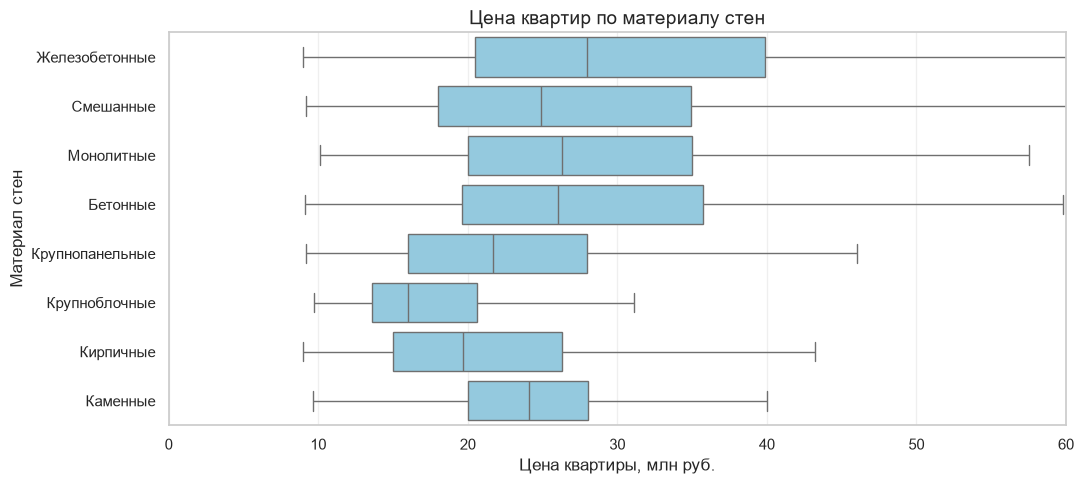

,median_price_mln_rub
wall_material,
Крупноблочные,16.00
Кирпичные,19.70
Крупнопанельные,21.70
Каменные,24.11
Смешанные,24.90
Бетонные,26.01
Монолитные,26.30
Железобетонные,28.00


In [6]:
# Сравниваем цену по материалу стен (шкала — в млн руб., до 100 млн)
# Словарь соответствия кода материала стен его названию
WALL_MATERIAL_NAMES = {
    '61001001000': 'Каменные',
    '61001001001': 'Кирпичные',
    '61001003000': 'Смешанные',
    '61001006000': 'Бетонные',
    '61001006001': 'Монолитные',
    '61001007000': 'Железобетонные',
    '61001007001': 'Крупнопанельные',
    '61001007004': 'Крупноблочные',
}
plot_df = df.dropna(subset=['wall_material_code', 'price']).copy()
plot_df['price_mln'] = plot_df['price'] / 1_000_000
# Заменяем коды стен их названиями, чтобы подписи на диаграмме были читаемыми
plot_df['wall_material'] = plot_df['wall_material_code'].map(WALL_MATERIAL_NAMES).fillna('Прочие')
median_prices = plot_df.groupby('wall_material')['price_mln'].median().sort_values()

if not median_prices.empty:
    plt.figure(figsize=(11, max(5, 0.35 * len(median_prices))))
    ax = sns.boxplot(data=plot_df, y='wall_material', x='price_mln', color='skyblue', showfliers=False)
    plt.title('Цена квартир по материалу стен', fontsize=14)
    plt.xlabel('Цена квартиры, млн руб.')
    plt.ylabel('Материал стен')
    ax.set_xlim(0, 60)  # шкала цены — до 100 млн руб.
    plt.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    plt.show()
    display(median_prices.rename('median_price_mln_rub').round(2).to_frame())
else:
    print('Нет данных для графика по материалу стен.')

На графике можно сравнить распределение цен по материалам стен (на диаграмме подписаны материалы, а не коды). Шкала цены ограничена 100 млн руб. Разницу и её величину нужно интерпретировать по фактическому графику после запуска; заранее заданные проценты не используются.

### Цена квартиры в зависимости от района

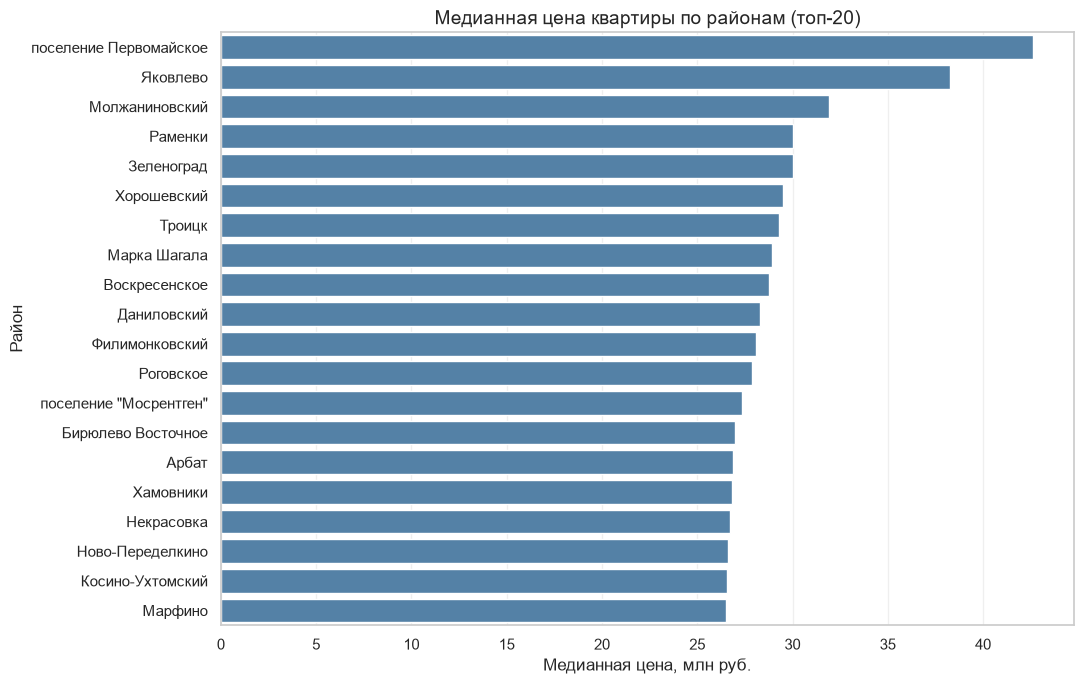

,median_price_mln_rub,object_count
district,,
поселение Первомайское,42.64,52
Яковлево,38.26,4
Молжаниновский,31.92,226
Раменки,30.00,2160
Зеленоград,30.00,1
Хорошевский,29.50,974
Троицк,29.30,4
Марка Шагала,28.90,5
Воскресенское,28.79,1


Районов с менее чем 10 сделками: 19


,median_price_mln_rub,object_count
district,,
Вороновское,22.38,1
Десеновское,12.80,1
Воскресенское,28.79,1
Зеленоград,30.00,1
Кокошкино,15.17,1
Рязановское,24.87,1
Роговское,27.86,1
Филимонковское,15.20,1
Южнопортовы,12.00,1


In [7]:
# Медианная цена по районам (в млн рублей)
plot_df = df.dropna(subset=['district', 'price']).copy()

stats = (
    plot_df.groupby('district')['price']
    .agg(['median', 'count'])
    .sort_values('median', ascending=False)
    .head(20)
)

# Переводим медианную цену из рублей в млн рублей
stats['median'] = stats['median'] / 1_000_000

plt.figure(figsize=(11, max(5, 0.35 * len(stats))))

ax = sns.barplot(
    x=stats['median'].values,
    y=stats.index.astype(str),
    color='steelblue'
)

plt.title('Медианная цена квартиры по районам (топ-20)', fontsize=14)
plt.xlabel('Медианная цена, млн руб.')
plt.ylabel('Район')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

display(
    stats.rename(columns={
        'median': 'median_price_mln_rub',
        'count': 'object_count'
    }).round({'median_price_mln_rub': 2})
)

# Районы с количеством сделок меньше 10
low_deals = (
    plot_df.groupby('district')['price']
    .agg(['median', 'count'])
    .sort_values('count', ascending=True)
)
low_deals = low_deals[low_deals['count'] < 10].copy()
low_deals['median'] = low_deals['median'] / 1_000_000
print(f"Районов с менее чем 10 сделками: {len(low_deals)}")
display(
    low_deals.rename(columns={
        'median': 'median_price_mln_rub',
        'count': 'object_count'
    }).round({'median_price_mln_rub': 2})
)

На графике показана медианная цена по районам. Вывод о том, какие районы дороже, делается по результатам фактического расчёта на загруженном датасете.

Далее посмотрим, как площадь квартиры связана со стоимостью.

### Цена квартиры в зависимости от площади

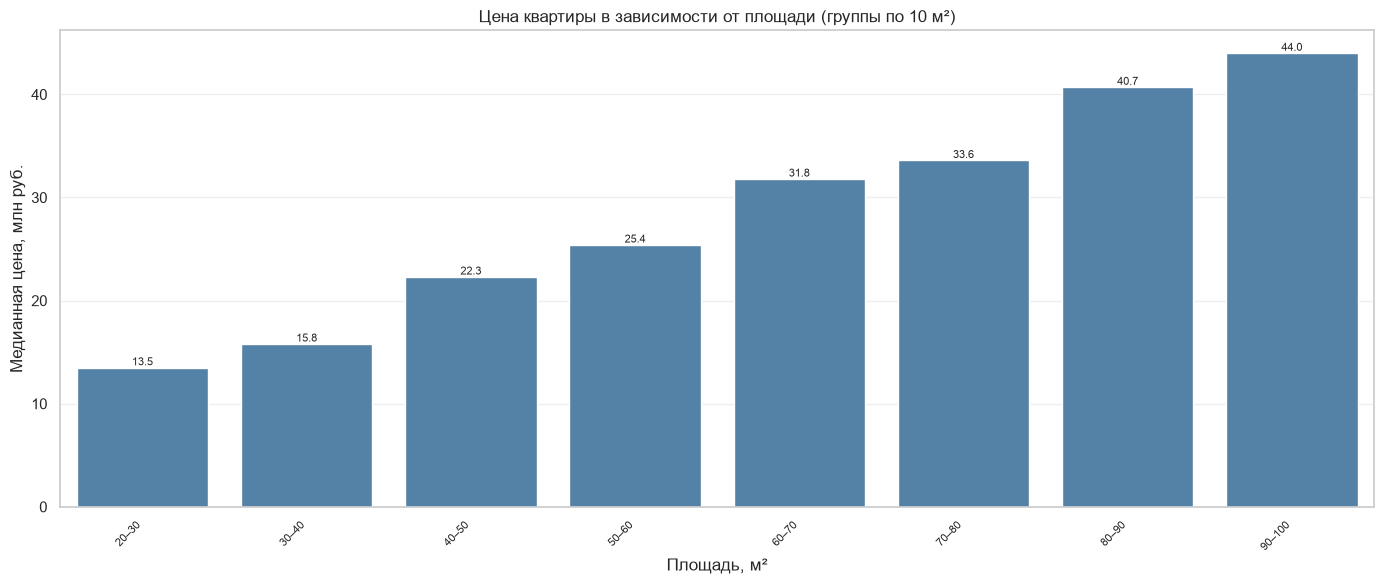

In [8]:
# Делим площадь на группы по 10 м² (цена — в млн руб.)
plot_df = df.dropna(subset=['area', 'price']).copy()
if plot_df['area'].nunique() >= 2:
    # Интервалы по 10 м²
    bins = list(range(0, 301, 10))
    plot_df['area_category'] = pd.cut(plot_df['area'], bins=bins)
    stats = plot_df.groupby('area_category', observed=True)['price'].median() / 1_000_000
    stats = stats.dropna()
    x_labels = [f'{int(interval.left)}–{int(interval.right)}' for interval in stats.index]

    plt.figure(figsize=(14, 6))
    ax = sns.barplot(x=x_labels, y=stats.values, color='steelblue')
    plt.title('Цена квартиры в зависимости от площади (группы по 10 м²)')
    plt.xlabel('Площадь, м²')
    plt.ylabel('Медианная цена, млн руб.')
    plt.xticks(rotation=45, ha='right', fontsize=8)
    plt.grid(axis='y', alpha=0.3)
    for i, value in enumerate(stats.values):
        ax.text(i, value, f'{value:,.1f}', ha='center', va='bottom', fontsize=8)
    plt.tight_layout()
    plt.show()
else:
    print('Недостаточно различных значений площади для построения групп.')


Сравнение медианной цены по группам площади позволяет оценить связь площади и стоимости. Конкретные выводы делаются после построения графика.

### Стоимость квартир в зависимости от этажа

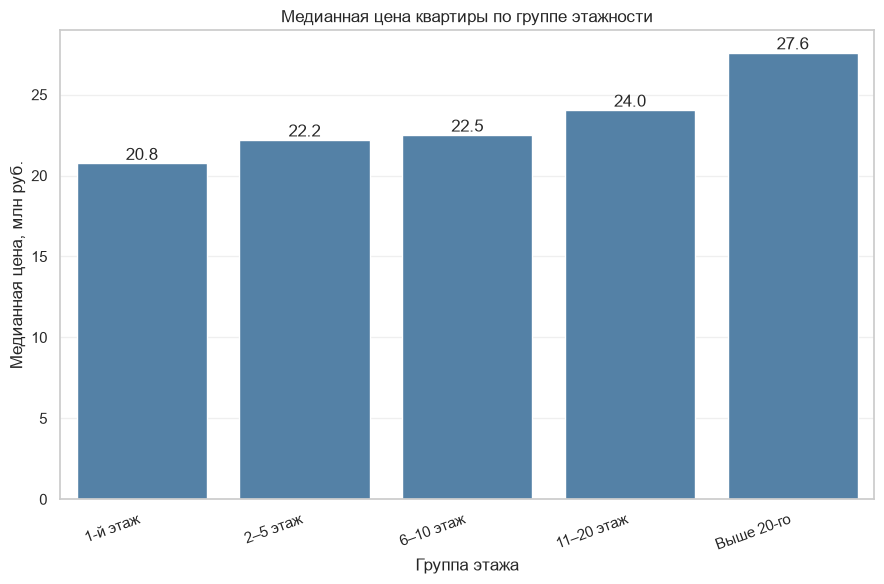

In [9]:
# Здесь floor — фактический номер этажа, а не бинарный признак (цена — в млн руб.)
plot_df = df.dropna(subset=['floor', 'price']).copy()
plot_df['floor_group'] = pd.cut(
    plot_df['floor'], bins=[0, 1, 5, 10, 20, np.inf],
    labels=['1-й этаж', '2–5 этаж', '6–10 этаж', '11–20 этаж', 'Выше 20-го'],
    include_lowest=True
)
stats = plot_df.groupby('floor_group', observed=True)['price'].median() / 1_000_000

if not stats.empty:
    plt.figure(figsize=(9, 6))
    ax = sns.barplot(x=stats.index.astype(str), y=stats.values, color='steelblue')
    plt.title('Медианная цена квартиры по группе этажности')
    plt.xlabel('Группа этажа')
    plt.ylabel('Медианная цена, млн руб.')
    plt.xticks(rotation=20, ha='right')
    plt.grid(axis='y', alpha=0.3)
    for i, value in enumerate(stats.values):
        ax.text(i, value, f'{value:,.1f}', ha='center', va='bottom')
    plt.tight_layout()
    plt.show()
else:
    print('Нет данных для анализа этажа.')


График сравнивает медианную цену объектов по этажам. Различия не следует заранее задавать фиксированными процентами: они рассчитываются по фактическим данным.

### Корреляционный анализ

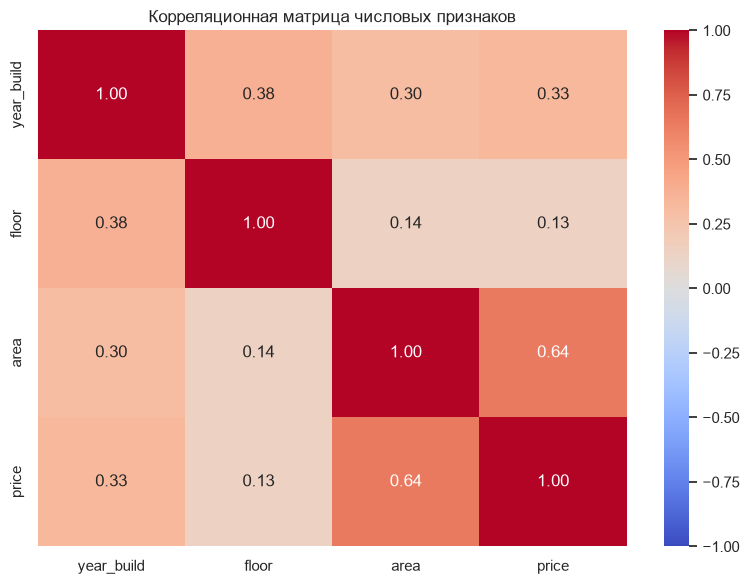

Корреляция признаков с целевой переменной price:
price         1.000
area          0.645
year_build    0.331
floor         0.133
Name: price, dtype: float64


In [10]:
# Для корреляции используем числовые признаки и целевую переменную
numeric_cols = ['year_build', 'floor', 'area', 'price']
df_corr = df[numeric_cols].copy()
corr_matrix = df_corr.corr(numeric_only=True)

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Корреляционная матрица числовых признаков')
plt.tight_layout()
plt.show()

print('Корреляция признаков с целевой переменной price:')
print(corr_matrix['price'].sort_values(ascending=False).round(3))


## Подготовка признаков для моделей

Для цены используем исходные характеристики квартиры, год сделки и возраст дома на момент сделки. Категориальные признаки кодируются внутри `Pipeline`, чтобы кодирование обучалось только на обучающей выборке и не заглядывало в тест. 
`street` включаем как категориальный признак. Если улиц очень много, one-hot кодирование может быть объёмным, но оно не присваивает улицам ложный числовой порядок.

In [11]:
model_df = model_source.copy()
for col in ["region", "district", "street", "wall_material_code"]:
    model_df[col] = model_df[col].astype("string").fillna("Неизвестно").astype(str)

categorical_cols = ["region", "district", "street", "wall_material_code"]
numeric_cols = ["year_build", "floor", "area", "period_year", "building_age"]
feature_cols = categorical_cols + numeric_cols
model_df = model_df.dropna(subset=["price", "period_year", "area"]).sort_values("period_start_date").reset_index(drop=True)

try:
    onehot = OneHotEncoder(handle_unknown="ignore", min_frequency=2, sparse_output=False)
except TypeError:
    onehot = OneHotEncoder(handle_unknown="ignore", min_frequency=2, sparse=False)

preprocessor = ColumnTransformer([
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("onehot", onehot)]), categorical_cols),
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median"))]), numeric_cols)
], remainder="drop")

print("Строк для моделирования:", len(model_df))
print("Категориальные признаки:", categorical_cols)
print("Числовые признаки:", numeric_cols)
display(model_df[feature_cols + ["price","price_per_sqm"]].head())

Строк для моделирования: 60328
Категориальные признаки: ['region', 'district', 'street', 'wall_material_code']
Числовые признаки: ['year_build', 'floor', 'area', 'period_year', 'building_age']


,region,district,street,wall_material_code,year_build,floor,area,period_year,building_age,price,price_per_sqm
0,ЮАО,Бирюлево Западное,Медынская,61001001000,2000,12,29,2023,23,15037477.0,518533.689655
1,ЮЗАО,Южное Бутово,Скобелевская,61001001001,2000,11,51,2023,23,18701547.0,366697.0
2,ЮВАО,Выхино-Жулебино,Ферганская,61001001001,2000,18,45,2023,23,18184474.0,404099.422222
3,ЮЗАО,Южное Бутово,Скобелевская,61001001001,2000,10,51,2023,23,18701547.0,366697.0
4,ЮЗАО,Академический,Винокурова,61001001000,2004,3,65,2023,19,24080067.0,370462.569231


## Временное разделение: обучаемся на прошлом, проверяем на будущем

Случайное разбиение здесь не подходит: оно может поместить сделки одного года и в обучение, и в тест, а это делает оценку слишком оптимистичной. Основной тест — последний доступный год строго меньше 2026 года. Модель обучается только на годах до тестового. Для содержательной оценки необходимо достаточно данных минимум за два года до 2026-го.

In [12]:
available_years = sorted(int(y) for y in model_df["period_year"].dropna().unique() if int(y) < 2026)
if len(available_years) < 2:
    raise ValueError("Нужно не менее двух разных годов сделок до 2026 года.")
test_year = available_years[-1]
train_df = model_df[model_df["period_year"] < test_year].copy()
test_df = model_df[model_df["period_year"] == test_year].copy()

if len(train_df) < 30 or len(test_df) < 5:
    candidates = [y for y in available_years[1:]
                  if (model_df["period_year"] < y).sum() >= 30 and (model_df["period_year"] == y).sum() >= 5]
    if candidates:
        test_year = candidates[-1]
        train_df = model_df[model_df["period_year"] < test_year].copy()
        test_df = model_df[model_df["period_year"] == test_year].copy()

if train_df.empty or test_df.empty:
    raise ValueError("Не удалось сформировать временные train/test выборки. Проверьте годы в period_start_date.")

X_train, y_train = train_df[feature_cols], np.log1p(train_df["price"].astype(float))
X_test, y_test = test_df[feature_cols], test_df["price"].astype(float)

print(f"Год тестирования: {test_year}")
print(f"Обучение: годы {train_df.period_year.min()}–{train_df.period_year.max()}, строк {len(train_df):,}")
print(f"Тест: {test_year}, строк {len(test_df):,}")

Год тестирования: 2025
Обучение: годы 2023–2024, строк 21,166
Тест: 2025, строк 23,715


## Обучение модели с заранее известными параметрами

Лучшие параметры уже определены ранее, поэтому повторный поиск гиперпараметров и сравнение нескольких моделей не выполняются. Здесь сразу обучается `HistGradientBoostingRegressor` с фиксированными параметрами. Далее эта модель используется для оценки прогнозов, исторического backtest и прогноза на будущие годы.

In [13]:
# Лучшие параметры заданы заранее — повторный поиск и сравнение моделей не нужны.
from sklearn.ensemble import HistGradientBoostingRegressor

KNOWN_BEST_PARAMS = {
    "model__max_leaf_nodes": 63,
    "model__max_iter": 150,
    "model__learning_rate": 0.08,
    "model__l2_regularization": 1.0
}
best_model_name = "HistGradientBoosting"

best_estimator_fixed = HistGradientBoostingRegressor(
    max_leaf_nodes=KNOWN_BEST_PARAMS["model__max_leaf_nodes"],
    max_iter=KNOWN_BEST_PARAMS["model__max_iter"],
    learning_rate=KNOWN_BEST_PARAMS["model__learning_rate"],
    l2_regularization=KNOWN_BEST_PARAMS["model__l2_regularization"],
    random_state=RANDOM_STATE
)
best_pipeline_fixed = Pipeline([("prep", preprocessor), ("model", best_estimator_fixed)])
best_pipeline_fixed.fit(X_train, y_train)

# Совместимость с последующими ячейками, которые используют best_search.best_estimator_.
best_search = type("FixedBestModel", (), {})()
best_search.best_estimator_ = best_pipeline_fixed
best_search.best_params_ = KNOWN_BEST_PARAMS

print("Модель обучена с заранее заданными параметрами:")
display(pd.DataFrame({"Параметр": list(KNOWN_BEST_PARAMS.keys()),
                      "Значение": list(KNOWN_BEST_PARAMS.values())}))


Модель обучена с заранее заданными параметрами:


,Параметр,Значение
0,model__max_leaf_nodes,63.00
1,model__max_iter,150.00
2,model__learning_rate,0.08
3,model__l2_regularization,1.00


## Почему выбрана эта модель: сравнение графиками и точность по каждому объекту

 Сравниваем MAE и RMSE в млн рублей, MAPE в процентах, затем строим диаграмму «факт против прогноза», график остатков и столбчатую диаграмму фактической/прогнозной цены для первых 10 тестовых квартир. Для каждого объекта показываются абсолютная ошибка в млн рублей, абсолютная процентная ошибка и условная процентная точность `max(0, 100 − процентная ошибка)`. Единый показатель точности прогнозов — `Accuracy = 100% − MAPE`.

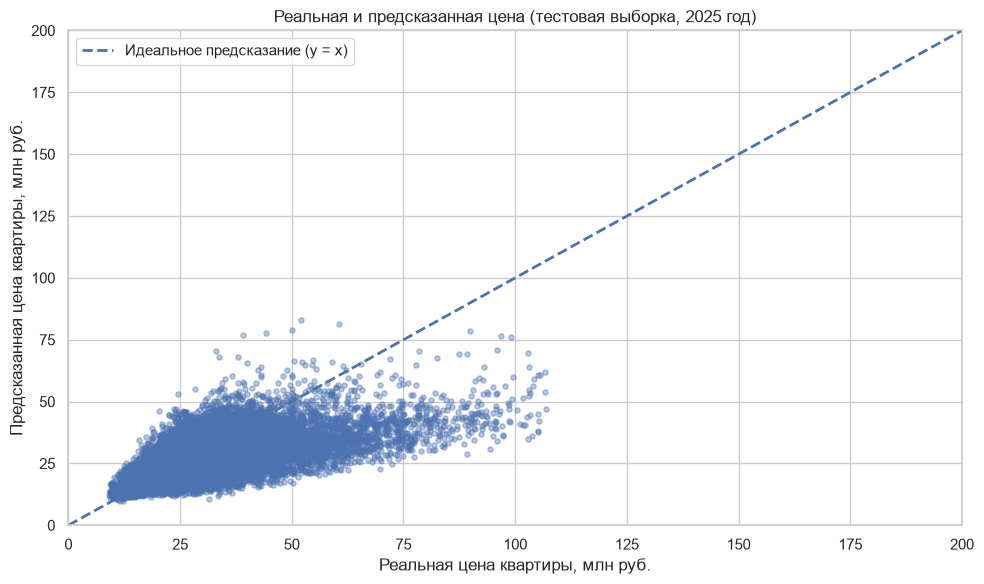

In [14]:

# Диагностика качества лучшей модели: реальная и прогнозируемая цена (в млн руб.),
# графики «факт против прогноза», остатков и столбчатое сравнение первых объектов.
# Исключаем ЦАО из тестовой оценки (по запросу пользователя).
not_cao = test_df["region"].astype(str) != "ЦАО"
X_test = X_test[not_cao]
test_df = test_df[not_cao]
y_test = test_df["price"].astype(float)

pred_test = np.maximum(0, np.expm1(best_pipeline_fixed.predict(X_test)))
actual_test = y_test.to_numpy()
abs_pct_error = np.abs(pred_test - actual_test) / np.maximum(actual_test, 1) * 100
object_accuracy_pct = np.clip(100 - abs_pct_error, 0, 100)

comparison = pd.DataFrame({
    'real_mln': actual_test / 1e6,
    'predicted_mln': pred_test / 1e6,
})
comparison['error_mln'] = comparison['real_mln'] - comparison['predicted_mln']
comparison['error_pct'] = comparison['error_mln'].abs() / comparison['real_mln'].replace(0, np.nan) * 100

AXIS_LIMIT_MLN = 200  # шкала графиков цены — до 200 млн руб.

# 1) Факт против прогноза (тестовая выборка)
plt.figure(figsize=(10, 6))
plt.scatter(comparison['real_mln'], comparison['predicted_mln'], alpha=0.4, s=14)
plt.plot([0, AXIS_LIMIT_MLN], [0, AXIS_LIMIT_MLN], linestyle='--', linewidth=2, label='Идеальное предсказание (y = x)')
plt.xlim(0, AXIS_LIMIT_MLN)
plt.ylim(0, AXIS_LIMIT_MLN)
plt.xlabel('Реальная цена квартиры, млн руб.')
plt.ylabel('Предсказанная цена квартиры, млн руб.')
plt.title(f'Реальная и предсказанная цена (тестовая выборка, {test_year} год)')
plt.legend(); plt.grid(True); plt.tight_layout(); plt.show()


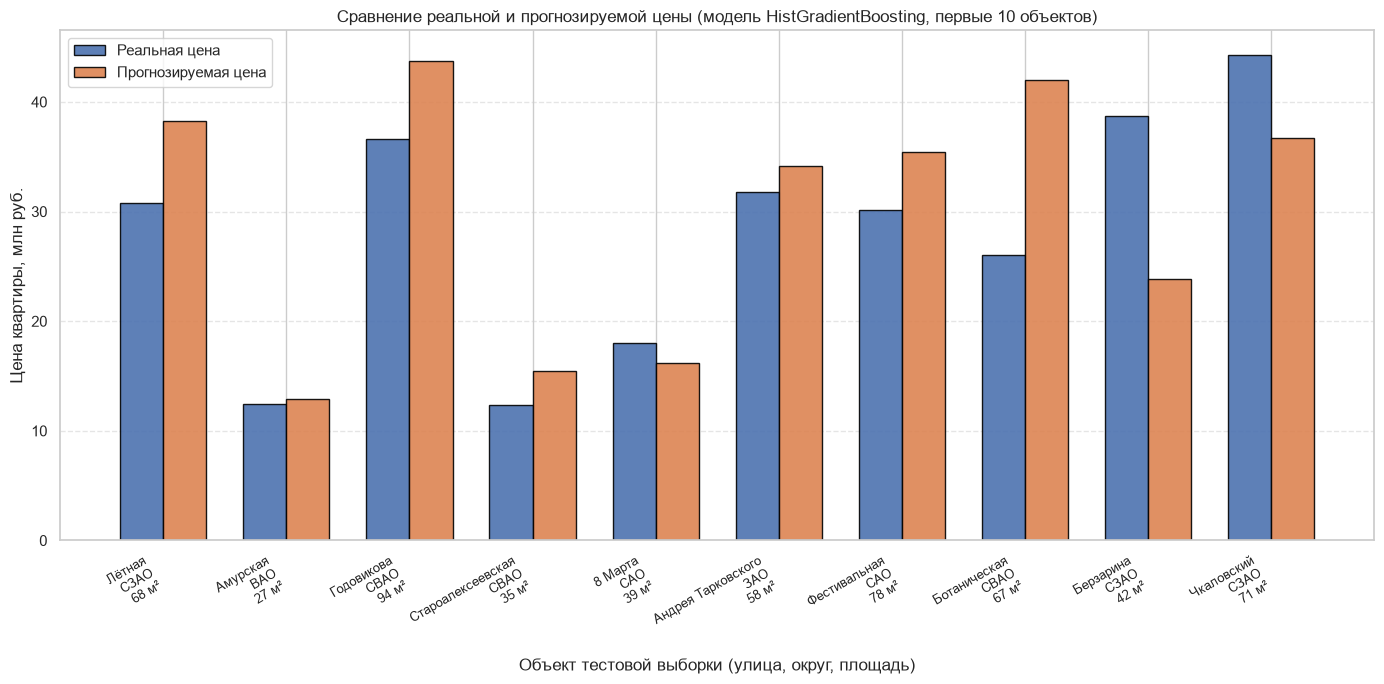

,"MAE, млн руб.","RMSE, млн руб.","MAPE, %",R²
0,6.56,10.28,21,0.47



Статистика ошибок модели (в млн руб.):
MAE = 6.56 млн руб.
Максимальная абсолютная ошибка = 67.83 млн руб.
Средняя ошибка = 1.85 млн руб.

Относительные показатели:
MAPE = 21%

Точность прогнозов (accuracy):
Accuracy = 79%


In [15]:
# 3) Столбчатая диаграмма: реальная и прогнозируемая цена первых 10 объектов
n = min(10, len(comparison))
sample = comparison.head(n).copy()
if n > 0:
    # Осмысленные подписи: улица, округ и площадь каждого объекта из тестовой выборки
    info = X_test.head(n)
    labels = [f'{s}\n{r}\n{a:.0f} м²' for s, r, a in zip(info['street'], info['region'], info['area'])]
    x = np.arange(n)
    width = 0.35
    plt.figure(figsize=(14, 7))
    plt.bar(x - width / 2, sample['real_mln'], width, label='Реальная цена', alpha=0.9, edgecolor='black')
    plt.bar(x + width / 2, sample['predicted_mln'], width, label='Прогнозируемая цена', alpha=0.9, edgecolor='black')
    plt.xlabel('Объект тестовой выборки (улица, округ, площадь)')
    plt.ylabel('Цена квартиры, млн руб.')
    plt.title(f'Сравнение реальной и прогнозируемой цены (модель {best_model_name}, первые {n} объектов)')
    plt.xticks(x, labels, rotation=30, ha='right', fontsize=9)
    plt.legend()
    plt.grid(axis='y', linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()
else:
    print('Нет тестовых объектов для визуализации.')

# Сводные метрики качества на отложенном тестовом периоде.
test_metrics = pd.DataFrame([{
    "MAE, млн руб.": mean_absolute_error(actual_test, pred_test)/1e6,
    "RMSE, млн руб.": np.sqrt(mean_squared_error(actual_test, pred_test))/1e6,
    "MAPE, %": round(float(np.mean(abs_pct_error))),
    "R²": r2_score(actual_test, pred_test) if len(actual_test) > 1 else np.nan
}])
display(test_metrics.round(2))

print('\nСтатистика ошибок модели (в млн руб.):')
print(f"MAE = {comparison['error_mln'].abs().mean():.2f} млн руб.")
print(f"Максимальная абсолютная ошибка = {comparison['error_mln'].abs().max():.2f} млн руб.")
print(f"Средняя ошибка = {comparison['error_mln'].mean():.2f} млн руб.")
print('\nОтносительные показатели:')
print(f"MAPE = {comparison['error_pct'].mean():.0f}%")

# Единый показатель точности прогнозов: Accuracy = 100% − MAPE
print('\nТочность прогнозов (accuracy):')
accuracy = 100 - comparison['error_pct'].mean()
print(f'Accuracy = {accuracy:.0f}%')

## Проверка на нескольких исторических годах (rolling-origin)

Один тестовый год может оказаться необычным. Дополнительно проверяем несколько исторических лет: для каждого года обучаем модель только на более ранних данных и оцениваем следующий год. Для этой дополнительной диагностики используем уже выбранный тип модели и параметры, найденные на основном train. Результаты показывают, насколько качество стабильно во времени. Эти оценки не заменяют основной тест, если доступно мало лет.

In [16]:
# Rolling-origin проверка фиксированной HistGradientBoosting.
# Для каждого года < 2026 модель обучается только на предыдущих годах.
# Данные 2026 не входят в историческую оценку качества.
from sklearn.base import clone

rolling_rows = []
rolling_years = [int(y) for y in available_years if int(y) > min(available_years)]
rolling_years = rolling_years[-5:]

for yr in rolling_years:
    tr = model_df[model_df["period_year"] < yr].copy()
    te = model_df[model_df["period_year"] == yr].copy()
    # Исключаем ЦАО из оценки (по запросу пользователя).
    tr = tr[tr["region"].astype(str) != "ЦАО"]
    te = te[te["region"].astype(str) != "ЦАО"]
    if len(tr) < 30 or len(te) < 5:
        continue
    fitted = clone(best_pipeline_fixed)
    fitted.fit(tr[feature_cols], np.log1p(tr["price"].astype(float)))
    p = np.maximum(0, np.expm1(fitted.predict(te[feature_cols])))
    a = te["price"].to_numpy()
    ape = np.abs(a-p)/np.maximum(a, 1)*100
    rolling_rows.append({
        "Тестовый год": int(yr),
        "Строк теста": len(te),
        "MAE, млн руб.": mean_absolute_error(a,p)/1e6,
        "RMSE, млн руб.": np.sqrt(mean_squared_error(a,p))/1e6,
        "MAPE, %": round(float(np.mean(ape))),
        "R²": r2_score(a,p) if len(a)>1 else np.nan
    })

rolling_results = pd.DataFrame(rolling_rows)


## Проверка прогноза на несколько лет вперёд на исторических периодах

Базовый прогноз цены проверяется на тестовых сделках, а для горизонта N лет отдельно запускаем исторический эксперимент: берём только сделки до выбранного года-отправной точки, обучаем уже выбранную HistGradientBoosting с найденными параметрами и предсказываем цены сделок в последующих годах. Проверка выполняется по рынку Москвы, тестовые сделки берутся из всех остальных округов. В таблицу включаются только годы с более чем 1000 сделок; если сделок больше 1500, берётся 1500 репрезентативных сделок (случайный отбор с фиксированным seed). Затем сравниваем медиану фактических цен и медиану прогнозов по каждому горизонту. Все денежные значения на графиках и в таблице — полная цена квартиры в млн рублей, а процентная ошибка рассчитана отдельно.

,region,district,Год обучения до,Год проверки,"Горизонт, лет",Сделок,"Фактическая медиана, млн руб.","Прогнозная медиана, млн руб.","MAE, млн руб.","MAPE, %","Accuracy, %",R²
0,ВАО,Восточное Измайлово,2023,2024,1,1600,22.2,23.00,2.27,8,92,0.75
1,ВАО,Восточное Измайлово,2023,2025,2,1600,21.9,22.58,2.17,8,92,0.75
2,ВАО,Восточное Измайлово,2024,2025,1,1600,21.9,21.99,0.40,2,98,1.00


Общая точность прогнозирования по backtest: Accuracy = 92%, MAE = 1.61 млн руб., R² = 0.83


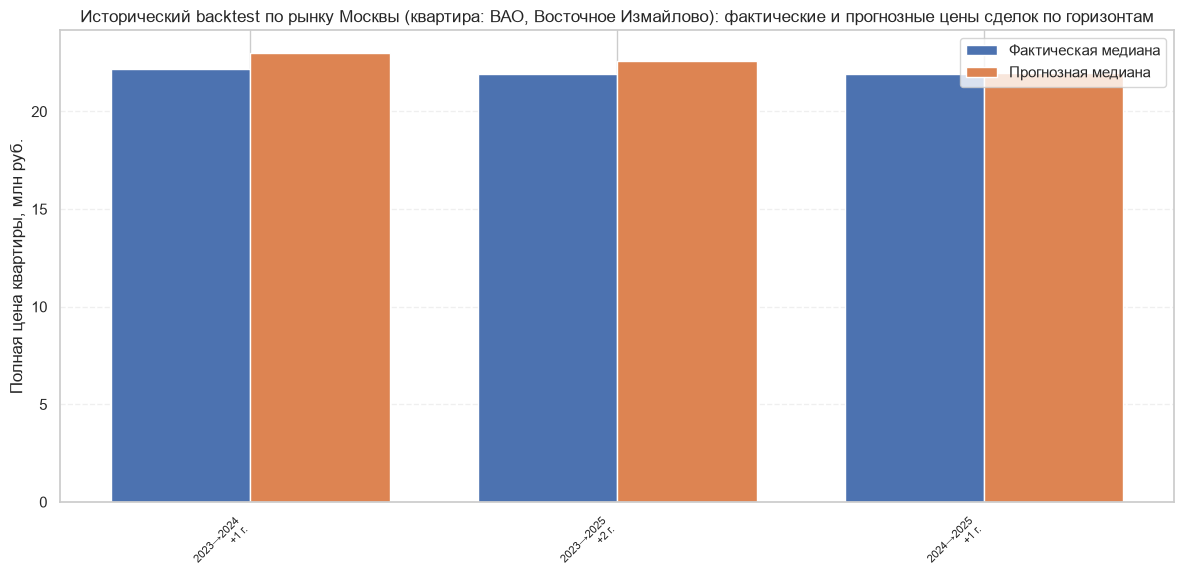

In [17]:
# Настройка горизонта проверки: можно поменять число лет.
BACKTEST_HORIZON = 5
BACKTEST_TRAIN_CAP = 1600  # ограничение выборки до этого числа сделок
BACKTEST_MIN_DEALS = 1000  # минимум сделок в тестовом году для включения строки в таблицу
historical_only = model_df[model_df["period_year"] < 2026].copy()
hist_years = sorted(historical_only["period_year"].dropna().astype(int).unique())
backtest_rows = []

def sample_typical(df, n=BACKTEST_TRAIN_CAP, value_col="price_per_sqm"):
    """Репрезентативная выборка до n сделок: n значений, ближайших к медиане
    (без самых дешёвых и самых дорогих сделок)."""
    if len(df) <= n:
        return df
    if value_col not in df.columns:
        value_col = "price"
    values = df[value_col].to_numpy()
    median_value = float(np.median(values))
    idx = np.argsort(np.abs(values - median_value), kind="stable")[:n]
    return df.iloc[np.sort(idx)].copy()

# Исключаем ЦАО из backtest (по запросу пользователя).
EXCLUDE_REGIONS = ["ЦАО"]

# Округ и район рассматриваемой квартиры (из APARTMENT, если он уже задан).
_apt = globals().get("APARTMENT", {})
bt_region = str(_apt.get("region", "ВАО"))
bt_district = str(_apt.get("district", "Восточное Измайлово"))

if len(hist_years) >= 3:
    # Каждый origin — год, к концу которого модель могла бы быть обучена.
    # Для честной проверки тестовые сделки должны быть позже origin.
    origins = hist_years[:-1]
    # Чтобы время выполнения было приемлемым, используем максимум последние 5 origin years.
    origins = origins[-5:]
    for origin_year in origins:
        train_bt = historical_only[historical_only["period_year"] <= origin_year].copy()
        # Исключаем ЦАО из обучения.
        train_bt = train_bt[~train_bt["region"].astype(str).isin(EXCLUDE_REGIONS)]
        # Ограничение обучающей выборки до 1500 сделок.
        train_bt = sample_typical(train_bt)
        if len(train_bt) < 30:
            continue
        model_bt = clone(best_pipeline_fixed)
        model_bt.fit(train_bt[feature_cols], np.log1p(train_bt["price"].astype(float)))
        future_years = [y for y in hist_years if origin_year < y <= origin_year + BACKTEST_HORIZON]
        for target_year in future_years:
            # Тестовые сделки — весь рынок Москвы (все округа и районы).
            test_bt = historical_only[historical_only["period_year"] == target_year].copy()
            test_bt = test_bt[~test_bt["region"].astype(str).isin(EXCLUDE_REGIONS)]
            # В таблицу включаем только годы с более чем 1000 сделок.
            if len(test_bt) <= BACKTEST_MIN_DEALS:
                continue
            # Если сделок больше 1500 — берём 1500 репрезентативных сделок.
            test_bt = sample_typical(test_bt)
            pred_bt = np.maximum(0, np.expm1(model_bt.predict(test_bt[feature_cols])))
            actual_bt = test_bt["price"].to_numpy()
            ape_bt = np.abs(actual_bt-pred_bt)/np.maximum(actual_bt,1)*100
            backtest_rows.append({
                "region": bt_region,
                "district": bt_district,
                "Год обучения до": int(origin_year),
                "Год проверки": int(target_year),
                "Горизонт, лет": int(target_year-origin_year),
                "Сделок": int(len(test_bt)),
                "Фактическая медиана, млн руб.": float(np.median(actual_bt)/1e6),
                "Прогнозная медиана, млн руб.": float(np.median(pred_bt)/1e6),
                "MAE, млн руб.": float(mean_absolute_error(actual_bt,pred_bt)/1e6),
                "MAPE, %": round(float(np.mean(ape_bt))),
                "Accuracy, %": round(float(100 - np.mean(ape_bt))),
                "R²": float(r2_score(actual_bt, pred_bt)) if len(actual_bt) > 1 else np.nan
            })

backtest_n_years = pd.DataFrame(backtest_rows)
if not backtest_n_years.empty:
    display(backtest_n_years.round(2))
    # Общая точность прогнозирования по backtest: Accuracy = наиболее частое значение (мода).
    acc_mode = backtest_n_years["Accuracy, %"].round(0).mode().iloc[0]
    print(f"Общая точность прогнозирования по backtest: "
          f"Accuracy = {acc_mode:.0f}%, "
          f"MAE = {backtest_n_years['MAE, млн руб.'].mean():.2f} млн руб., "
          f"R² = {backtest_n_years['R²'].mean():.2f}")
    # Для наглядности показываем прогнозные и фактические медианы по каждому историческому прогнозу.
    plot_bt = backtest_n_years.sort_values(["Год обучения до","Год проверки"]).reset_index(drop=True)
    labels_bt = [f'{r["Год обучения до"]}→{r["Год проверки"]}\n+{r["Горизонт, лет"]} г.' for _,r in plot_bt.iterrows()]
    xx = np.arange(len(plot_bt)); width=.38
    plt.figure(figsize=(max(12,len(plot_bt)*.65),6))
    plt.bar(xx-width/2, plot_bt["Фактическая медиана, млн руб."], width, label="Фактическая медиана")
    plt.bar(xx+width/2, plot_bt["Прогнозная медиана, млн руб."], width, label="Прогнозная медиана")
    plt.xticks(xx, labels_bt, rotation=45, ha="right", fontsize=8)
    plt.ylabel("Полная цена квартиры, млн руб.")
    plt.title(f"Исторический backtest по рынку Москвы (квартира: {bt_region}, {bt_district}): фактические и прогнозные цены сделок по горизонтам")
    plt.legend(); plt.grid(axis="y", linestyle="--", alpha=.3); plt.tight_layout(); plt.show()
else:
    print("Для многошаговой исторической проверки недостаточно периодов или сделок.")

## Финальное обучение для практического прогноза

Историческую точность мы измеряли на данных, не участвовавших в обучении. После выбора типа модели и гиперпараметров можно переобучить её на всех доступных строках, чтобы использовать максимум информации для будущего прогноза. Это финальная модель для применения; её нельзя использовать вместо исторического теста при отчёте о точности.

In [18]:
from sklearn.base import clone
final_model = clone(best_search.best_estimator_)
final_model.fit(model_df[feature_cols], np.log1p(model_df["price"].astype(float)))
print(f"Финальная модель {best_model_name} обучена на {len(model_df):,} строках "
      f"за {model_df['period_year'].min()}–{model_df['period_year'].max()} годы.")

Финальная модель HistGradientBoosting обучена на 60,328 строках за 2023–2026 годы.


## Динамика рынка по каждому региону и району

Для каждой группы `region × год` и `region × district × год` вычисляем внутренний индикатор рынка — медиану цены за м², коэффициент изменения относительно предыдущего доступного года и процент изменения. В итоговых таблицах и графиках выводим только коэффициент, процент изменения и число сделок; денежные значения цены за м² остаются техническими величинами для расчёта темпа рынка. Исторические выводы ограничены годами строго меньше 2026.

In [19]:
# Цена за м² используется только как внутренний индикатор темпа рынка.
# В итоговых выводах и графиках стоимости квартиры отображаем полную цену в млн руб.
annual_region = (model_source.groupby(["region","period_year"], dropna=False)
                 .agg(median_price_per_sqm=("price_per_sqm","median"), deals=("price_per_sqm","size"))
                 .reset_index().sort_values(["region","period_year"]))
annual_region["growth_factor"] = annual_region.groupby("region")["median_price_per_sqm"].transform(lambda s: s/s.shift(1))
annual_region["growth_pct"] = ((annual_region["growth_factor"]-1)*100).round(0).astype("Int64")
# Первый год наблюдений в группе: предыдущего года нет, поэтому роста нет (коэффициент 1.0, 0%).
# Заполняем вместо NA, чтобы в таблицах не было пропусков.
annual_region["growth_factor"] = annual_region["growth_factor"].fillna(1.0)
annual_region["growth_pct"] = annual_region["growth_pct"].fillna(0)
annual_region["has_prev_year"] = annual_region.groupby("region")["median_price_per_sqm"].transform(lambda s: s.shift(1).notna())

annual_district = (model_source.groupby(["region","district","period_year"], dropna=False)
                   .agg(median_price_per_sqm=("price_per_sqm","median"), deals=("price_per_sqm","size"))
                   .reset_index().sort_values(["region","district","period_year"]))
annual_district["growth_factor"] = annual_district.groupby(["region","district"])["median_price_per_sqm"].transform(lambda s: s/s.shift(1))
annual_district["growth_pct"] = ((annual_district["growth_factor"]-1)*100).round(0).astype("Int64")
annual_district["growth_factor"] = annual_district["growth_factor"].fillna(1.0)
annual_district["growth_pct"] = annual_district["growth_pct"].fillna(0)
annual_district["has_prev_year"] = annual_district.groupby(["region","district"])["median_price_per_sqm"].transform(lambda s: s.shift(1).notna())

# Исторические сводки ограничиваем периодом < 2026. Данные 2026 остаются для текущего прогноза.
annual_region_historical = annual_region[annual_region["period_year"] < 2026].copy()
annual_district_historical = annual_district[annual_district["period_year"] < 2026].copy()

print("Годовые коэффициенты изменения по region (расчёт внутренне основан на цене за м²; отображаем только коэффициент и процент):")
display(annual_region_historical[["region","period_year","deals","growth_factor","growth_pct"]].round(2))
print("Годовые коэффициенты изменения по region + district:")
display(annual_district_historical[["region","district","period_year","deals","growth_factor","growth_pct"]].round(2))

# В сводки включаем только годы, для которых есть предыдущий год (реальный темп изменения).
region_summary = (annual_region_historical[annual_region_historical["has_prev_year"]]
                  .groupby("region")
                  .agg(mean_annual_growth_pct=("growth_pct","mean"),
                       median_annual_growth_pct=("growth_pct","median"),
                       latest_year=("period_year","max"),
                       total_year_changes=("growth_pct","count"),
                       min_deals_per_year=("deals","min"))
                  .reset_index().sort_values("median_annual_growth_pct",ascending=False))
district_summary = (annual_district_historical[annual_district_historical["has_prev_year"]]
                    .groupby(["region","district"])
                    .agg(mean_annual_growth_pct=("growth_pct","mean"),
                         median_annual_growth_pct=("growth_pct","median"),
                         latest_year=("period_year","max"),
                         total_year_changes=("growth_pct","count"),
                         min_deals_per_year=("deals","min"))
                    .reset_index().sort_values("median_annual_growth_pct",ascending=False))
region_summary["mean_annual_growth_pct"] = region_summary["mean_annual_growth_pct"].round(0).astype(int)
region_summary["median_annual_growth_pct"] = region_summary["median_annual_growth_pct"].round(0).astype(int)
district_summary["mean_annual_growth_pct"] = district_summary["mean_annual_growth_pct"].round(0).astype(int)
district_summary["median_annual_growth_pct"] = district_summary["median_annual_growth_pct"].round(0).astype(int)
print("Сводка по регионам: темп изменения в процентах, без вывода цены за м².")
display(region_summary.round(2))
print("Районы: для интерпретации используйте минимум 2 годовых изменения и достаточное число сделок.")
display(district_summary.round(2))

Годовые коэффициенты изменения по region (расчёт внутренне основан на цене за м²; отображаем только коэффициент и процент):


,region,period_year,deals,growth_factor,growth_pct
0,ВАО,2023,342,1.0,0
1,ВАО,2024,1011,0.93,-7
2,ВАО,2025,1516,0.99,-1
4,ЗАО,2023,309,1.0,0
5,ЗАО,2024,3186,0.92,-8
6,ЗАО,2025,4168,1.02,2
8,ЗелАО,2024,152,1.0,0
9,ЗелАО,2025,161,1.0,0
11,НАО,2023,76,1.0,0
12,НАО,2024,1443,1.04,4


Годовые коэффициенты изменения по region + district:


,region,district,period_year,deals,growth_factor,growth_pct
0,ВАО,Богородское,2023,15,1.0,0
1,ВАО,Богородское,2024,140,0.83,-17
2,ВАО,Богородское,2025,211,0.96,-4
4,ВАО,Вешняки,2023,41,1.0,0
5,ВАО,Вешняки,2024,75,0.94,-6
...,...,...,...,...,...,...
555,ЮЗАО,Южное Бутово,2024,140,1.01,1
556,ЮЗАО,Южное Бутово,2025,160,1.04,4
558,ЮЗАО,Ясенево,2023,31,1.0,0
559,ЮЗАО,Ясенево,2024,63,1.21,21


Сводка по регионам: темп изменения в процентах, без вывода цены за м².


,region,mean_annual_growth_pct,median_annual_growth_pct,latest_year,total_year_changes,min_deals_per_year
3,НАО,4,4,2025,2,1248
9,ЮАО,1,1,2025,2,2158
2,ЗелАО,0,0,2025,1,161
10,ЮВАО,0,0,2025,2,1350
6,СЗАО,-2,-2,2025,2,1658
1,ЗАО,-3,-3,2025,2,3186
8,ЦАО,-3,-3,2025,2,1662
5,СВАО,-4,-4,2025,2,1591
0,ВАО,-4,-4,2025,2,1011
4,САО,-4,-4,2025,2,2071


Районы: для интерпретации используйте минимум 2 годовых изменения и достаточное число сделок.


,region,district,mean_annual_growth_pct,median_annual_growth_pct,latest_year,total_year_changes,min_deals_per_year
40,НАО,Первомайское,166,166,2024,1,1
37,НАО,Молжаниновский,122,122,2025,1,7
35,НАО,Внуковское,37,37,2024,1,41
16,ЗАО,Внуково,21,21,2025,2,3
87,ТАО,Бекасово,20,20,2025,1,25
...,...,...,...,...,...,...,...
34,НАО,Внуково,-23,-23,2025,1,1
43,НАО,поселение Внуковское,-27,-27,2025,1,1
33,ЗелАО,Старое Крюково,-29,-29,2025,1,22
38,НАО,Московский,-29,-29,2024,1,2


## Графики изменения рынка по region и district

Здесь отображается годовое процентное изменение, рассчитанное внутренне по медианному индикатору цены за м². В подписях, выводах и графиках полной стоимости не показываем цену за м². Для рейтинга районов оставляем только группы с минимум двумя годовыми изменениями и не менее чем 10 сделками в каждом доступном году — это уменьшает, но не устраняет нестабильность.

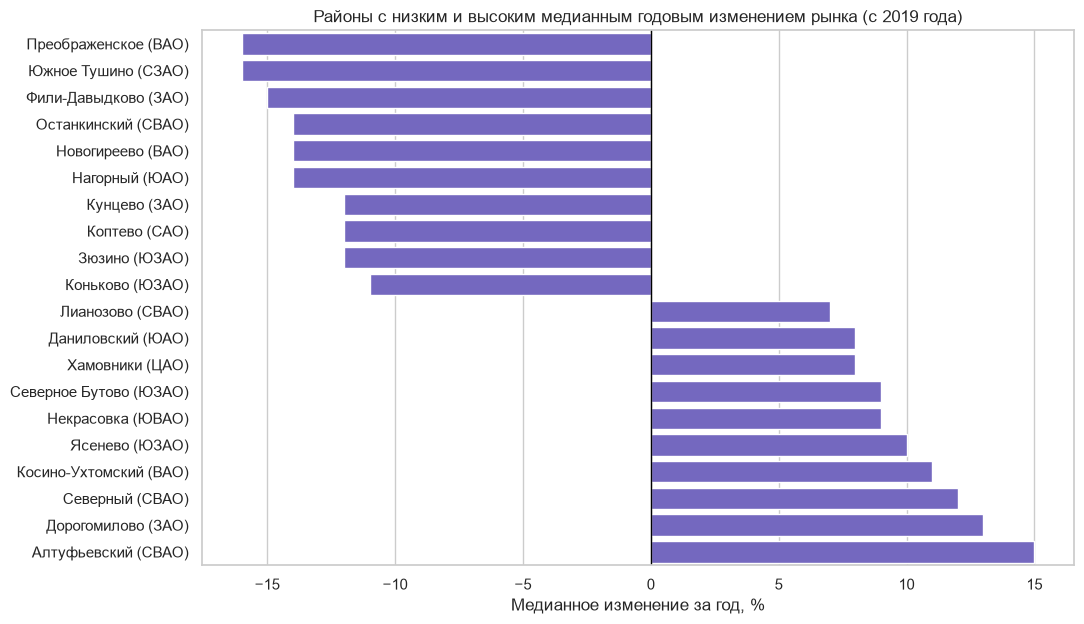

In [20]:
# Графики рыночной динамики показывают процент изменения, а не цену за м².
# Ограничиваем период с 2019 года: в более ранних годах лишь единичные сделки.
HIST_START_YEAR = 2019
region_hist_plot = annual_region_historical[annual_region_historical["period_year"] >= HIST_START_YEAR]
district_hist_plot = annual_district_historical[annual_district_historical["period_year"] >= HIST_START_YEAR]

# Сводку по районам пересчитываем только по периоду с 2019 года.
district_summary_2019 = (district_hist_plot[district_hist_plot["has_prev_year"]]
                         .groupby(["region","district"])
                         .agg(mean_annual_growth_pct=("growth_pct","mean"),
                              median_annual_growth_pct=("growth_pct","median"),
                              latest_year=("period_year","max"),
                              total_year_changes=("growth_pct","count"),
                              min_deals_per_year=("deals","min"))
                         .reset_index().sort_values("median_annual_growth_pct",ascending=False))
district_summary_2019["mean_annual_growth_pct"] = district_summary_2019["mean_annual_growth_pct"].round(0).astype(int)
district_summary_2019["median_annual_growth_pct"] = district_summary_2019["median_annual_growth_pct"].round(0).astype(int)
eligible_districts = district_summary_2019[
    (district_summary_2019["total_year_changes"] >= 2) &
    (district_summary_2019["min_deals_per_year"] >= 10)
].copy()
if not eligible_districts.empty:
    ranked = pd.concat([
        eligible_districts.nsmallest(10,"median_annual_growth_pct"),
        eligible_districts.nlargest(10,"median_annual_growth_pct")
    ]).drop_duplicates()
    ranked["label"] = ranked["district"].astype(str) + " (" + ranked["region"].astype(str) + ")"
    plt.figure(figsize=(11, max(5, len(ranked)*.32)))
    sns.barplot(data=ranked.sort_values("median_annual_growth_pct"),
                x="median_annual_growth_pct", y="label", color="slateblue")
    plt.axvline(0,color="black",linewidth=1)
    plt.title("Районы с низким и высоким медианным годовым изменением рынка (с 2019 года)")
    plt.xlabel("Медианное изменение за год, %"); plt.ylabel("")
    plt.tight_layout(); plt.show()
else:
    print("Недостаточно районов с минимум двумя годовыми изменениями и минимум 10 сделками в каждом наблюдаемом году (с 2019 года).")

## Параметры квартиры и горизонт прогноза

В ячейке ниже число лет `FORECAST_N` и характеристики квартиры `APARTMENT` задаются прямо в коде как константы. Измените их и выполните ячейку прогноза — построятся таблица и график роста цены в млн рублей.

In [21]:
# Параметры прогноза задаются прямо в коде (константы).
FORECAST_N = 5
APARTMENT = {
    "region": "ВАО",
    "district": "Восточное Измайлово",
    "street": "Первомайская",
    "wall_material_code": "61001007001",
    "year_build": 1969,
    "floor": 7,
    "area": 60.0,
}

print("Последний год в данных:", int(model_df["period_year"].max()))
display(pd.DataFrame([APARTMENT]))

Последний год в данных: 2026


,region,district,street,wall_material_code,year_build,floor,area
0,ВАО,Восточное Измайлово,Первомайская,61001007001,1969,7,60.0


## Расчёт инфляции по цене за м² (price/area)

Инфляция за каждый год рассчитывается как процентное изменение медианной цены за квадратный метр (`price / area`) к предыдущему году и округляется до целых процентов. Для расчёта используется полный датасет `СДЕЛКИ_Мос_2019-2026.csv` (8 лет истории вместо 4 в `model_source`), что даёт более надёжную оценку. Годы с малым числом сделок (менее 30) дают ненадёжную медиану, поэтому их инфляция заменяется средним уровнем (медианой по надёжным годам); первый год принимается за 0%. Нижняя граница инфляции — 7% в год: реальный рост цен на жильё в Москве не ниже 7% в год, а отрицательные значения в данных — артефакт смены состава сделок и качества данных.

In [22]:
# --- Расчёт инфляции на основе цены за м² (price/area) ---
# Используем полный датасет СДЕЛКИ_Мос_2019-2026.csv: 8 лет истории вместо 4
# (model_source содержит только 2023-2026), что даёт более надёжную оценку инфляции.
# Инфляция за год = % изменения медианной цены за м² к предыдущему году.
# Годы с малым числом сделок (ненадёжная медиана) заполняются средним уровнем инфляции.
# Нижняя граница 7% в год: реальный рост цен на жильё в Москве не ниже 7% в год;
# отрицательные значения в данных — артефакт смены состава сделок и качества данных.

INFLATION_DATA_PATH = Path("СДЕЛКИ_Мос_2019-2026.csv")
MIN_DEALS_FOR_INFLATION = 30   # минимум сделок в году для надёжной медианы
MIN_INFLATION_PCT = 7.0        # нижняя граница инфляции, % в год

# Загрузка датасета для расчёта инфляции (с запасным вариантом кодировки)
infl_raw = None
for sep in [";", ",", "\t"]:
    for encoding in ["utf-8-sig", "cp1251"]:
        try:
            infl_raw = pd.read_csv(INFLATION_DATA_PATH, sep=sep, encoding=encoding)
            if infl_raw.shape[1] >= 5:
                break
        except Exception:
            continue
    if infl_raw is not None and infl_raw.shape[1] >= 5:
        break
if infl_raw is None:
    raise FileNotFoundError(f"Не удалось прочитать {INFLATION_DATA_PATH}")

infl_raw["period_start_date"] = pd.to_datetime(infl_raw["period_start_date"], errors="coerce", dayfirst=True)
infl_raw["period_year"] = infl_raw["period_start_date"].dt.year
infl_raw["price_per_sqm"] = infl_raw["price"] / infl_raw["area"]
infl_raw = infl_raw[(infl_raw["price"] > 0) & (infl_raw["area"] > 0)].copy()

# Удаление выбросов (правило 3 сигм), как в основной очистке
for col in ["price", "price_per_sqm"]:
    m, s = infl_raw[col].mean(), infl_raw[col].std()
    infl_raw = infl_raw[(infl_raw[col] >= m - 3 * s) & (infl_raw[col] <= m + 3 * s)]

annual_market = (infl_raw.groupby("period_year")
                 .agg(median_price_per_sqm=("price_per_sqm", "median"),
                      deals=("price_per_sqm", "size"))
                 .reset_index().sort_values("period_year"))

# Инфляция за каждый год, %
annual_market["inflation_pct"] = annual_market["median_price_per_sqm"].pct_change() * 100

# Годы с малым числом сделок дают ненадёжную медиану — заменяем их средним уровнем
prev_deals = annual_market["deals"].shift(1)
unreliable = (annual_market["deals"] < MIN_DEALS_FOR_INFLATION) | (prev_deals < MIN_DEALS_FOR_INFLATION)
reliable_inflation = annual_market.loc[~unreliable, "inflation_pct"].dropna()
avg_inflation_level = float(reliable_inflation.median()) if len(reliable_inflation) else 0.0

annual_market.loc[unreliable, "inflation_pct"] = avg_inflation_level
# Первый год: предыдущего года нет — принимаем 0%
annual_market.loc[annual_market["period_year"] == annual_market["period_year"].min(), "inflation_pct"] = 0.0

# Нижняя граница инфляции: реальный рост цен на жильё в Москве не ниже 7% в год
annual_market["inflation_pct"] = annual_market["inflation_pct"].clip(lower=MIN_INFLATION_PCT)

# Округляем инфляцию до целых процентов
annual_market["inflation_pct"] = annual_market["inflation_pct"].round(0).astype(int)

# Темп снижения инфляции: изменение инфляции в процентных пунктах
annual_market["inflation_change_pp"] = annual_market["inflation_pct"].diff().fillna(0).round(0).astype(int)

print("Годовая инфляция по медианной цене за м² (price/area):")
display(annual_market)

# Средний уровень инфляции по надёжным годам (после нижней границы)
avg_inflation_level = float(annual_market.loc[~unreliable, "inflation_pct"].median())
print(f"Средний уровень инфляции: {avg_inflation_level:.0f}%")

Годовая инфляция по медианной цене за м² (price/area):


,period_year,median_price_per_sqm,deals,inflation_pct,inflation_change_pp
0,2019,484411.680707,1816,7,0
1,2020,473937.929511,4,7,0
2,2021,294904.445783,14,7,0
3,2022,404974.624294,3364,7,0
4,2023,405080.333333,3362,7,0
5,2024,320000.000000,14411,7,0
6,2025,340740.740741,15088,7,0
7,2026,378647.416413,7256,11,4


Средний уровень инфляции: 7%


## Прогноз цены квартиры на N лет и текстовое объяснение

Для прогноза на дальний горизонт нельзя просто подставить будущий год в дерево: деревья обычно не экстраполируют временной тренд за пределы обучающих лет. Поэтому строим базовую оценку выбранной квартиры лучшей моделью и корректируем её на коэффициент стоимости округа (region): модель обучается на всей Москве и склонна предсказывать среднюю цену, поэтому базовый прогноз квартиры умножается на коэффициент её округа (например, в ЦАО квартиры дороже). Будущую динамику рассчитываем по обоснованной инфляции: годовому проценту изменения медианной цены за м² (`price / area`) по рынку Москвы в целом. Инфляция за каждый год рассчитывается по фактическим данным (ненадёжные годы заполняются средним уровнем), затем прогнозируется по закономерности: последняя известная инфляция плавно сходится к среднему уровню инфляции. Каждый будущий год цена умножается на соответствующую спрогнозированную инфляцию.

In [23]:
def safe_cagr(values, years=None):
    """CAGR по значениям и годам. Возвращает np.nan, если данных недостаточно."""
    vals = pd.to_numeric(pd.Series(np.asarray(values).ravel()), errors="coerce")
    if years is None:
        yrs = pd.Series(np.arange(len(vals), dtype=float))
    else:
        yrs = pd.to_numeric(pd.Series(np.asarray(years).ravel()), errors="coerce")
    temp = pd.DataFrame({"value": vals.to_numpy(), "year": yrs.to_numpy()}).dropna()
    temp = temp[temp["value"] > 0].sort_values("year")
    if len(temp) < 2:
        return np.nan
    elapsed = float(temp["year"].iloc[-1] - temp["year"].iloc[0])
    if elapsed <= 0:
        return np.nan
    return float((temp["value"].iloc[-1] / temp["value"].iloc[0]) ** (1.0 / elapsed) - 1.0)


def cagr_by_year(table, year_col, value_col):
    """CAGR по таблице с колонками года и значения (например, медианной цены за м²)."""
    if table is None or len(table) == 0:
        return np.nan
    t = table[[year_col, value_col]].dropna().sort_values(year_col)
    t = t[t[value_col] > 0]
    if len(t) < 2:
        return np.nan
    return safe_cagr(t[value_col].to_numpy(), t[year_col].to_numpy())


# Ограничение годового темпа роста рынка: сценарное допущение против выбросов.
GROWTH_FLOOR, GROWTH_CAP = -0.15, 0.25


def estimate_market_cagr(region, district, min_deals=5):
    """CAGR медианного индикатора рынка: район -> округ -> весь рынок."""
    region_s, district_s = str(region), str(district)
    ad = globals().get("annual_district")
    ar = globals().get("annual_region")

    if ad is not None and len(ad):
        d = ad[(ad["region"].astype(str) == region_s) &
               (ad["district"].astype(str) == district_s)]
        d = d[d["deals"] >= min_deals]
        g = cagr_by_year(d, "period_year", "median_price_per_sqm")
        if pd.notna(g):
            return g, f"район «{district_s}»"

    if ar is not None and len(ar):
        r = ar[ar["region"].astype(str) == region_s]
        r = r[r["deals"] >= min_deals]
        g = cagr_by_year(r, "period_year", "median_price_per_sqm")
        if pd.notna(g):
            return g, f"округ «{region_s}»"

    market = (model_source.groupby("period_year")
              .agg(median_price_per_sqm=("price_per_sqm", "median"),
                   deals=("price_per_sqm", "size"))
              .reset_index())
    g = cagr_by_year(market, "period_year", "median_price_per_sqm")
    if pd.notna(g):
        return g, "рынок Москвы в целом"

    return 0.0, "нет данных (принят нулевой рост)"


def forecast_inflation_pct(annual_market, n_years, floor_pct=7.0, cap_pct=15.0, convergence=0.15, min_step_pp=0.2):
    """Прогноз инфляции на n_years лет.

    Последняя известная инфляция (годовой % изменения медианной цены за м²)
    плавно сходится к целевому уровню — медиане последних 3 надёжных лет.
    Темп изменения ~0.2–1.2 п.п. в год: шаг не меньше min_step_pp, пока
    инфляция выше целевого уровня. Результат ограничен [floor_pct; cap_pct].
    """
    hist = annual_market.dropna(subset=["inflation_pct"]).copy()
    if len(hist) < 1:
        return [], []
    last_year = int(hist["period_year"].iloc[-1])
    last_inflation = float(hist["inflation_pct"].iloc[-1])
    target = float(hist["inflation_pct"].tail(3).median())

    years = list(range(last_year + 1, last_year + int(n_years) + 1))
    inflations = []
    current = last_inflation
    for _ in years:
        step = (current - target) * convergence
        if current > target and step < min_step_pp:
            step = min_step_pp
        current = current - step
        current = float(np.clip(current, floor_pct, cap_pct))
        inflations.append(current)
    return years, inflations


def build_forecast(apartment, n_years, show_plot=True):
    """Базовая оценка квартиры лучшей моделью + рост по обоснованной инфляции на N лет."""
    global forecast_result

    base_year = int(model_df["period_year"].max())
    year_build = int(apartment["year_build"])
    row = {
        "region": str(apartment["region"]),
        "district": str(apartment["district"]),
        "street": str(apartment["street"]),
        "wall_material_code": str(apartment["wall_material_code"]),
        "year_build": year_build,
        "floor": int(apartment["floor"]),
        "area": float(apartment["area"]),
        "period_year": base_year,
        "building_age": max(0, base_year - year_build),
    }
    X_new = pd.DataFrame([row])[feature_cols]
    base_price = float(np.maximum(0.0, np.expm1(best_pipeline_fixed.predict(X_new)))[0])
    # Учёт коэффициента цены в округе (region): модель склонна предсказывать среднюю
    # по Москве цену, поэтому базовая оценка умножается на коэффициент округа квартиры.
    coef_region = float(region_price_coef.get(str(apartment["region"]), 1.0))
    base_price = base_price * coef_region

    # Прогноз инфляции на основе исторических данных по цене за м² (price/area)
    infl_years, infl_values = forecast_inflation_pct(annual_market, n_years)

    # Цена каждого года = базовая цена, умноженная на соответствующую инфляцию
    years = [base_year] + list(infl_years)
    prices = [base_price]
    for inf in infl_values:
        prices.append(prices[-1] * (1.0 + inf / 100.0))

    forecast_result = pd.DataFrame({
        "Год": years,
        "Прогноз цены, млн руб.": [round(p / 1e6, 2) for p in prices],
        # Базовый год: рост не применялся, поэтому инфляция 0% (без NA в таблице).
        "Инфляция, %": pd.Series([0] + [int(round(i)) for i in infl_values], dtype="Int64"),
    })

    print(f"Квартира: {apartment['region']}, {apartment['district']}, "
          f"{apartment['street']}, {apartment['area']:.0f} м², "
          f"{apartment['floor']} эт., {year_build} г.")
    print(f"Базовая оценка на {base_year} год: {base_price / 1e6:.2f} млн руб. "
          f"(коэффициент округа {apartment['region']} = {coef_region:.2f})")
    if infl_values:
        avg_level_disp = globals().get("avg_inflation_level", 0.0)
        # Темп изменения инфляции: среднее годовое изменение в п.п. (со знаком).
        # Например, 10% → 9% за 5 лет означает ~-0.3 п.п. в год.
        rate_of_change = float((infl_values[-1] - infl_values[0]) / len(infl_values)) if len(infl_values) > 1 else 0.0
        print(f"Прогноз инфляции (по медианной цене за м²): "
              f"{infl_values[0]:.0f}% → {infl_values[-1]:.0f}% "
              f"(средний уровень инфляции {avg_level_disp:.0f}%, "
              f"темп изменения ~{rate_of_change:.1f} п.п. в год)")
    display(forecast_result)

    if show_plot:
        plt.figure(figsize=(10, 5))
        plt.plot(forecast_result["Год"], forecast_result["Прогноз цены, млн руб."],
                 marker="o", color="seagreen", linewidth=2)
        for x, y in zip(forecast_result["Год"], forecast_result["Прогноз цены, млн руб."]):
            plt.annotate(f"{y:.2f}", (x, y), textcoords="offset points",
                         xytext=(0, 8), ha="center", fontsize=9)
        plt.title(f"Прогноз цены квартиры на {int(n_years)} лет "
                  f"({apartment['district']}, {apartment['area']:.0f} м²)")
        plt.xlabel("Год")
        plt.ylabel("Цена квартиры, млн руб.")
        plt.grid(alpha=0.3)
        plt.tight_layout()
        plt.show()

    return forecast_result

## Прогноз и сценарии роста

Прогноз строится по параметрам, заданным в коде. Дополнительно строим три сценария: низкий, базовый и высокий темп роста. Сценарии — не доверительные интервалы модели, а прозрачный анализ чувствительности к предположениям о рынке.

Квартира: ВАО, Восточное Измайлово, Первомайская, 60 м², 7 эт., 1969 г.
Базовая оценка на 2026 год: 27.12 млн руб. (коэффициент округа ВАО = 0.98)
Прогноз инфляции (по медианной цене за м²): 10% → 9% (средний уровень инфляции 7%, темп изменения ~-0.3 п.п. в год)


,Год,"Прогноз цены, млн руб.","Инфляция, %"
0,2026,27.12,0
1,2027,29.95,10
2,2028,32.91,10
3,2029,36.02,9
4,2030,39.29,9
5,2031,42.74,9


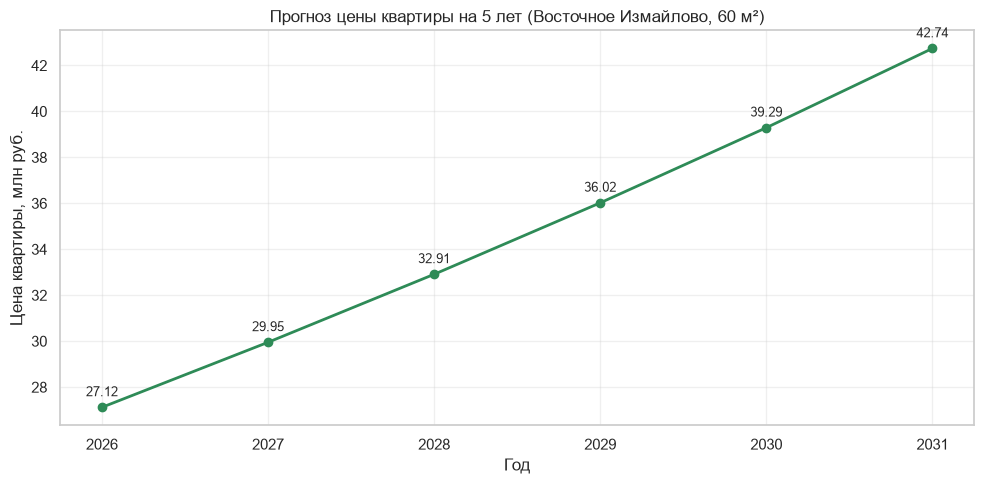

Общая точность модели прогнозирования: Accuracy = 79% (MAPE = 21%)


In [24]:
# Прогноз по параметрам, заданным прямо в коде (APARTMENT, FORECAST_N).
build_forecast(APARTMENT, FORECAST_N)

# Общая точность модели прогнозирования (на отложенном тестовом годе).
if "accuracy" in globals():
    print(f"Общая точность модели прогнозирования: Accuracy = {accuracy:.0f}% "
          f"(MAPE = {100 - accuracy:.0f}%)")

# Сценарии +/- 5 процентных пунктов от оценённого базового роста.
if "forecast_result" in globals():
    base_prices_mln = forecast_result["Прогноз цены, млн руб."].to_numpy()
    base_growth = 0.0
    if len(base_prices_mln) > 1 and base_prices_mln[0] > 0:
        base_growth = (base_prices_mln[1] / base_prices_mln[0]) - 1
    years_s = forecast_result["Год"].to_numpy()
    base_p = base_prices_mln[0] 
    scenario = pd.DataFrame({
        "Год": years_s,
        "Базовый сценарий, млн руб.": [base_p * (1 + base_growth) ** h for h in range(len(years_s))],
    })
